In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [4]:
df= pd.read_csv(r"C:\Users\ADMIN\Desktop\Protein_Expression_Yield_Prediction\Data\protein_expression.csv")
df.head(3)

,No,Protein,Signal_peptide,Signal_peptide_target_protein_sequence,Media,OD_au,IPTG_mM,Temperature_C,Time_h,Maximum_expression_yield_mg_L,Level,References
0,1,"Xylanase, xynA2",ompA,MKKTAIAIAVALAGFATVAQAMQTTPNSEG WHDGYYYSWWSDGGA...,LB,3,1,20,2,692.8,H,[1]
1,2,Human interleukin 6,phoA,MKQSTIALALLPLLFTPVTKAMPVPPGEDSKD VAAPHRQPLTSSE...,LB,0.5,1,22/37,4,0,L,[2]
2,3,Candida antarctica lipase B (CALB),pelB,MKYLLPTAAAGLLLLAAQPAMALPSGSDPA FSQPKSVLDAGLTCQ...,LB,0.5- 0.6,1,16,24,5.2,M,[3]


In [5]:
target = "Maximum_expression_yield_mg_L"

# Convert simple numeric values; ranges become NaN for now
df["Yield_clean"] = pd.to_numeric(df[target], errors="coerce")

print("Valid numeric yields:", df["Yield_clean"].notna().sum())
print("Values requiring review:", df["Yield_clean"].isna().sum())


Valid numeric yields: 78
Values requiring review: 19


In [6]:
df=df.dropna(subset=["Yield_clean"])
print("Values requiring review:", df["Yield_clean"].isna().sum())

Values requiring review: 0


In [7]:
features =df [["Media","OD_au","IPTG_mM", "Temperature_C", "Time_h","Yield_clean" ]]
features.head(3)

,Media,OD_au,IPTG_mM,Temperature_C,Time_h,Yield_clean
0,LB,3,1,20,2,692.8
1,LB,0.5,1,22/37,4,0.0
2,LB,0.5- 0.6,1,16,24,5.2


In [8]:
features.info()

<class 'pandas.DataFrame'>
Index: 78 entries, 0 to 93
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Media          77 non-null     str    
 1   OD_au          78 non-null     str    
 2   IPTG_mM        78 non-null     str    
 3   Temperature_C  78 non-null     str    
 4   Time_h         78 non-null     str    
 5   Yield_clean    78 non-null     float64
dtypes: float64(1), str(5)
memory usage: 5.4 KB


In [9]:
# Convert numerical columns to numeric data types
num_features = ["OD_au", "IPTG_mM", "Temperature_C", "Time_h"]

for col in num_features:
    features[col] = pd.to_numeric(features[col], errors="coerce")


In [10]:
features.info()

<class 'pandas.DataFrame'>
Index: 78 entries, 0 to 93
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Media          77 non-null     str    
 1   OD_au          46 non-null     float64
 2   IPTG_mM        70 non-null     float64
 3   Temperature_C  68 non-null     float64
 4   Time_h         66 non-null     float64
 5   Yield_clean    78 non-null     float64
dtypes: float64(5), str(1)
memory usage: 4.5 KB


In [11]:
cat_features = ["Media"]

# Preprocessing

preprocessor = ColumnTransformer([
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown ="ignore"))
]), cat_features),

    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy ="median")),
        ("scaler", StandardScaler())
        ]), num_features)

    ])

In [12]:
# Sepearte feature and targetr
X= features.drop(columns ='Yield_clean')
y= features['Yield_clean']


In [13]:
X_train, X_test, y_train, y_test =train_test_split(X,y,test_size = 0.2,random_state=42)


In [14]:
# Define models
models = {"Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200,random_state=42),
    "SVR": SVR(kernel="rbf"),
    "XGBoost": XGBRegressor(n_estimators=200,max_depth=4,learning_rate=0.05,random_state=42)

}

results = []
trained_models = {}

# Train and evaluate each model
for name, regressor in models.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

    # Train each model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Evaluate
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # storing the result
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = model

    print(f"\n{name}")
    print("MAE:", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2 Score:", round(r2, 4))


Linear Regression
MAE: 123.7103
RMSE: 221.6842
R2 Score: 0.1693

Random Forest
MAE: 124.6985
RMSE: 235.2791
R2 Score: 0.0643

SVR
MAE: 124.9606
RMSE: 270.9895
R2 Score: -0.2413

XGBoost
MAE: 126.8738
RMSE: 246.6788
R2 Score: -0.0286


In [15]:
print("====Final Model Comparison====")
Performance_result = pd.DataFrame(results)
Performance_result = Performance_result.sort_values(by ="MAE", ascending= True)

print(Performance_result)


====Final Model Comparison====
               Model         MAE        RMSE  R2 Score
0  Linear Regression  123.710265  221.684212  0.169284
1      Random Forest  124.698487  235.279106  0.064272
2                SVR  124.960645  270.989522 -0.241332
3            XGBoost  126.873798  246.678838 -0.028601


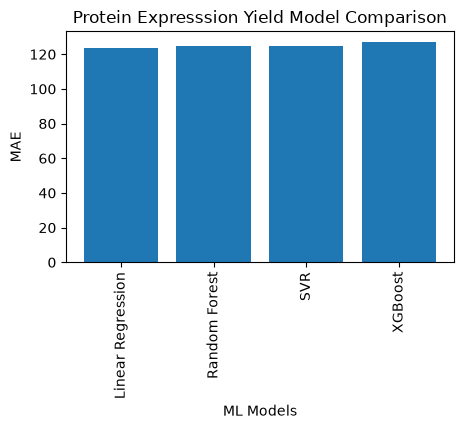

In [16]:
# Visualize the comparison
plt.figure(figsize=(5,3))

plt.bar(Performance_result['Model'], Performance_result['MAE'])
plt.title("Protein Expresssion Yield Model Comparison")
plt.xlabel("ML Models")
plt.ylabel("MAE")
plt.xticks(rotation=90)
plt.show()

In [17]:
# Select the best model
best_model_name = Performance_result.iloc[0]["Model"]
best_model = trained_models[best_model_name]
print("Best model based on MAE:", best_model_name)

import os
# Create the folder if it doesn't exist
os.makedirs("Model_comparison", exist_ok=True)

# Save comparison result in csv
Performance_result.to_csv("Model_comparison/Comparison Result of Models", index=False)

Best model based on MAE: Linear Regression


In [18]:
# Save model
import joblib
import os

# Create the folder if it doesn't exist
os.makedirs("Model", exist_ok=True)


joblib.dump(best_model, "Model/Protein_Expression_yield_model.pkl")
print("Model Save Successfully")

Model Save Successfully


In [27]:
# Predict the yield for new data
import pandas as pd
import joblib

# Load the saved model
model = joblib.load(
    r"C:\Users\ADMIN\Desktop\Protein_Expression_Yield_Prediction\Notebooks\Model\Protein_Expression_yield_model.pkl")

# Enter new experimental conditions
media = 'LB'
od = 0.8
iptg = 1
temperature = 30 
time = 4

# Create input DataFrame
new_data = pd.DataFrame([{
    "Media": media,
    "OD_au": od,
    "IPTG_mM": iptg,
    "Temperature_C": temperature,
    "Time_h": time
}])

# Predict protein expression yield
predicted_yield = model.predict(new_data)

print("\n===== Prediction Result =====")
print(f"Predicted Expression Yield: {predicted_yield[0]:.2f} mg/L")



===== Prediction Result =====
Predicted Expression Yield: 75.94 mg/L
